# Chapitre 18 - Exercices 18.1 à 18.5

- 18.1 : ridge très régularisée et PLS à une composante ;
- 18.2 : centroïdes réduits et lasso ;
- 18.3 : contrainte de somme nulle dans la multinomiale ridge ;
- 18.4 : formule de calcul (18.15) de la ridge ;
- 18.5 : le théorème de réduction (18.16)-(18.17).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## Exercice 18.1 : Ridge pour $\lambda\to\infty$ et PLS à une composante

**Énoncé (reformulé).** Pour un vecteur de coefficients $\hat\beta$, on note
$\hat\beta/\|\hat\beta\|_2$ sa version normalisée. Montrer que, lorsque
$\lambda\to\infty$, les coefficients ridge normalisés convergent vers les
coefficients normalisés de la régression PLS (moindres carrés partiels) à **une
composante**.

**Rappels.**

- Ridge : $\hat\beta_\lambda = (\mathbf X^T\mathbf X+\lambda I)^{-1}\mathbf X^Ty$.
- PLS (algorithme 3.3 du livre), avec des colonnes $x_j$ standardisées et $y$
  centré : la première direction a pour poids $\hat\varphi_{1j} = \langle x_j, y\rangle$,
  la première composante est $z_1 = \sum_j\hat\varphi_{1j}x_j = \mathbf X\mathbf X^Ty$,
  et l'on régresse $y$ sur $z_1$ : $\hat\theta_1 = \langle z_1,y\rangle/\langle z_1,z_1\rangle$.
  L'ajustement à une composante est $\hat y = \hat\theta_1 z_1 = \mathbf X(\hat\theta_1\mathbf X^Ty)$,
  donc les coefficients (dans l'espace des $x_j$) sont
  $$\hat\beta^{\mathrm{PLS}} = \hat\theta_1\,\mathbf X^Ty .$$

**Solution.**

*Coefficients PLS normalisés.* On a
$\hat\theta_1 = \frac{y^T\mathbf X\mathbf X^Ty}{\|z_1\|^2} = \frac{\|\mathbf X^Ty\|^2}{\|z_1\|^2}\ge 0$.
Si $\mathbf X^Ty\neq 0$, alors $\hat\theta_1 > 0$ et
$$\frac{\hat\beta^{\mathrm{PLS}}}{\|\hat\beta^{\mathrm{PLS}}\|} = \frac{\mathbf X^Ty}{\|\mathbf X^Ty\|}.$$

*Ridge pour $\lambda$ grand.* On factorise $\lambda$ :
$$\lambda\hat\beta_\lambda = \lambda(\mathbf X^T\mathbf X + \lambda I)^{-1}\mathbf X^Ty = \Big(I + \tfrac1\lambda\mathbf X^T\mathbf X\Big)^{-1}\mathbf X^Ty .$$
Quand $\lambda\to\infty$, $I + \frac1\lambda\mathbf X^T\mathbf X\to I$, et l'inversion
est continue au voisinage de $I$ ; donc $\lambda\hat\beta_\lambda\to\mathbf X^Ty$.
Plus précisément, pour $\lambda > \|\mathbf X^T\mathbf X\|$ (norme d'opérateur), la série
de Neumann donne
$$\lambda\hat\beta_\lambda = \mathbf X^Ty - \frac1\lambda\mathbf X^T\mathbf X\,\mathbf X^Ty + O(\lambda^{-2}).$$

*Passage à la normalisation.* La normalisation est invariante par multiplication par
un scalaire positif : $\hat\beta_\lambda/\|\hat\beta_\lambda\| = \lambda\hat\beta_\lambda/\|\lambda\hat\beta_\lambda\|$.
L'application $v\mapsto v/\|v\|$ étant continue en tout $v\ne 0$, on obtient
$$\frac{\hat\beta_\lambda}{\|\hat\beta_\lambda\|}\ \xrightarrow[\lambda\to\infty]{}\ \frac{\mathbf X^Ty}{\|\mathbf X^Ty\|} = \frac{\hat\beta^{\mathrm{PLS}}}{\|\hat\beta^{\mathrm{PLS}}\|}. \qquad\square$$

> **Intuition.** Quand la pénalité domine, $\mathbf X^T\mathbf X$ devient négligeable
> devant $\lambda I$ : la ridge « oublie » les corrélations entre variables et chaque
> coefficient devient proportionnel à la covariance univariée $\langle x_j, y\rangle$,
> exactement comme la première direction PLS.

**Vérification numérique** sur les données *prostate* (8 variables standardisées) et
sur un cas simulé avec $p = 500 > N = 40$. On trace $1 - \cos(\hat\beta_\lambda, \mathbf X^Ty)$.

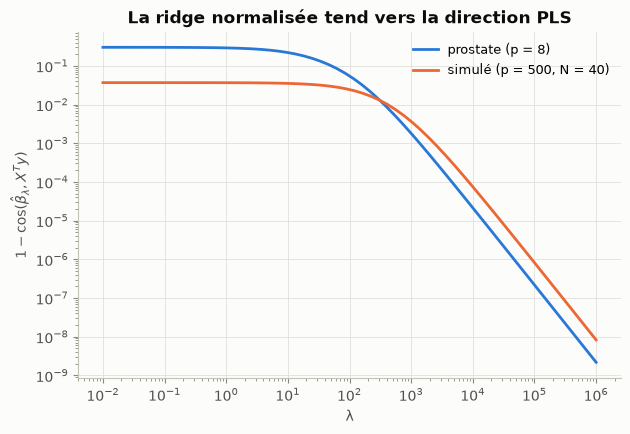

In [2]:
pro = datasets.load_prostate()
Xp = pro.drop(columns=["lpsa", "train"]).to_numpy(float)
Xp = (Xp - Xp.mean(0)) / Xp.std(0)
yp = pro["lpsa"].to_numpy() - pro["lpsa"].mean()
rng = np.random.RandomState(0)
Xh = rng.randn(40, 500)
Xh = (Xh - Xh.mean(0)) / Xh.std(0)
yh = Xh[:, :10].sum(1) + rng.randn(40)
yh -= yh.mean()

lams = np.logspace(-2, 6, 60)
fig, ax = plt.subplots(figsize=(7, 4.5))
for (X, y, name), c in zip([(Xp, yp, "prostate (p = 8)"), (Xh, yh, "simulé (p = 500, N = 40)")],
                           [BLUE, ORANGE]):
    pls = X.T @ y / np.linalg.norm(X.T @ y)
    B = g.ridge_svd(X, y, lams)
    cos = (B @ pls) / np.linalg.norm(B, axis=1)
    ax.loglog(lams, 1 - cos, color=c, label=name)
ax.set_xlabel("λ")
ax.set_ylabel(r"$1 - \cos(\hat\beta_\lambda, X^T y)$")
ax.set_title("La ridge normalisée tend vers la direction PLS")
ax.legend()
plt.show()

La distance angulaire décroît vers 0 comme $1/\lambda^2$ pour $\lambda$ grand (pente
$-2$ en log-log : $1-\cos\theta\approx\theta^2/2$ et l'angle $\theta$ est en $O(1/\lambda)$).

> **À retenir.** Les deux extrémités du chemin ridge sont la solution des moindres
> carrés de norme minimale ($\lambda\to 0$, exercice 18.7) et, à normalisation près,
> la direction PLS $\mathbf X^Ty$ ($\lambda\to\infty$).

## Exercice 18.2 : Centroïdes réduits et lasso

**Énoncé (reformulé).** Modèle de Bayes naïf gaussien : les variables
$j = 1,\dots,p$ sont indépendantes dans chaque classe $k = 1,\dots,K$, et pour
$i\in C_k$ (les $N_k$ indices de la classe $k$),
$x_{ij}\sim\mathcal N(\mu_j+\mu_{jk},\sigma_j^2)$ avec $\sum_k\mu_{jk} = 0$. On prend
$\hat\sigma_j = s_j$ (écart-type intra-classe poolé) et l'on considère le problème de
type lasso (éq. (18.55))
$$\min_{\{\mu_j,\mu_{jk}\}}\ \frac12\sum_{j=1}^p\sum_{k=1}^K\sum_{i\in C_k}\frac{(x_{ij}-\mu_j-\mu_{jk})^2}{s_j^2} + \lambda\sqrt{N_k}\sum_{j=1}^p\sum_{k=1}^K\frac{|\mu_{jk}|}{s_j}.$$
Montrer que la solution coïncide avec les centroïdes réduits (18.5), avec $s_0 = 0$ et
$m_k^2 = 1/N_k$ au lieu de $1/N_k - 1/N$.

**Rappel : le lasso à une variable.** Pour $a\in\mathbb R$ et $t\ge0$, la fonction
$h(\mu) = \frac12(a-\mu)^2 + t|\mu|$ est minimale en $\hat\mu = \operatorname{sign}(a)(|a|-t)_+$
(seuillage doux). *Preuve par cas* :

- sur $\mu > 0$, $h$ est dérivable, $h'(\mu) = \mu - a + t$, nulle en $\mu = a - t$, ce
  qui n'est admissible que si $a > t$ ;
- sur $\mu < 0$, $h'(\mu) = \mu - a - t$, nulle en $\mu = a + t$, admissible seulement si $a < -t$ ;
- si $|a|\le t$, $h$ est décroissante sur $]-\infty,0]$ et croissante sur $[0,\infty[$
  (signes de $h'$ ci-dessus), donc le minimum est en $\mu = 0$.

$h$ étant strictement convexe, ce minimum est unique.

**Solution.**

*Étape 1 : séparation.* Le critère est une somme de termes ne faisant intervenir que
les paramètres d'une variable $j$ : on peut minimiser variable par variable. On fixe
$j$ et l'on note $\bar x_{kj}$ la moyenne de la classe $k$ et $\bar x_j$ la moyenne globale.

*Étape 2 : le niveau commun $\mu_j$.* Comme dans les centroïdes réduits (18.4)-(18.7),
où l'on rétrécit les centroïdes de classe **vers le centroïde global**, on fixe
$\hat\mu_j = \bar x_j$ (c'est l'estimateur du maximum de vraisemblance de $\mu_j$ quand
$\lambda = 0$ et que la contrainte s'écrit $\sum_kN_k\mu_{jk} = 0$).

*Étape 3 : décomposition de König-Huygens.* Pour $\mu$ réel,
$$\sum_{i\in C_k}(x_{ij}-\bar x_j-\mu)^2 = \sum_{i\in C_k}(x_{ij}-\bar x_{kj})^2 + N_k(\bar x_{kj}-\bar x_j-\mu)^2,$$
car le terme croisé $2(\bar x_{kj}-\bar x_j-\mu)\sum_{i\in C_k}(x_{ij}-\bar x_{kj})$ est nul.
Le premier terme ne dépend pas de $\mu$. Pour chaque classe $k$, il reste donc à minimiser
$$\frac{N_k}{2s_j^2}(a_{kj}-\mu_{jk})^2 + \frac{\lambda\sqrt{N_k}}{s_j}|\mu_{jk}|,\qquad a_{kj} = \bar x_{kj}-\bar x_j .$$

*Étape 4 : seuillage doux.* En divisant par $N_k/s_j^2 > 0$, on obtient
$\frac12(a_{kj}-\mu_{jk})^2 + \frac{\lambda s_j}{\sqrt{N_k}}|\mu_{jk}|$, donc d'après le rappel
$$\hat\mu_{jk} = \operatorname{sign}(a_{kj})\Big(|a_{kj}| - \frac{\lambda s_j}{\sqrt{N_k}}\Big)_+ .$$
Posons $m_k = 1/\sqrt{N_k}$ et $d_{kj} = a_{kj}/(m_ks_j)$, c'est-à-dire (18.4) avec $s_0 = 0$.
En divisant par $m_ks_j > 0$ :
$$\frac{\hat\mu_{jk}}{m_ks_j} = \operatorname{sign}(d_{kj})\big(|d_{kj}| - \lambda\big)_+ = d'_{kj}\quad\text{avec }\Delta = \lambda,$$
et le centroïde estimé de la classe $k$ est $\hat\mu_j + \hat\mu_{jk} = \bar x_j + m_ks_jd'_{kj}$ :
c'est exactement (18.7). $\square$

> **Remarque.** Le facteur $\sqrt{N_k}$ dans la pénalité sert à exprimer le seuil en
> unités d'écart-type de $\bar x_{kj}$ (qui vaut $s_j/\sqrt{N_k}$). La version du cours
> utilise $m_k^2 = 1/N_k - 1/N$, qui tient compte en plus de l'aléa de $\bar x_j$
> (voir le calcul de variance du cours 1).

**Vérification numérique** : on résout chaque problème unidimensionnel par une
minimisation numérique générique et on compare à `NearestShrunkenCentroids` avec
`s0=0` et `mk="lasso"`, sur 200 gènes de NCI (8 classes).

In [3]:
X_all, lab_all = datasets.load_nci()
types, counts = np.unique(lab_all, return_counts=True)
keep = np.isin(lab_all, types[counts >= 5])
Xn, yn = X_all[keep][:, :200], lab_all[keep]
lam = 1.5
nsc = g.NearestShrunkenCentroids(delta=lam, s0=0.0, mk="lasso").fit(Xn, yn)
xbar = Xn.mean(0)
max_gap = 0.0
for j in range(Xn.shape[1]):
    for k, c in enumerate(nsc.classes_):
        xk, sj = Xn[yn == c, j], nsc.s_[j]
        crit = lambda mu: 0.5 * np.sum((xk - xbar[j] - mu) ** 2) / sj ** 2 \
            + lam * np.sqrt(len(xk)) * abs(mu) / sj
        res = optimize.minimize_scalar(crit, bounds=(-10, 10), method="bounded",
                                       options={"xatol": 1e-10})
        max_gap = max(max_gap, abs(res.x - (nsc.shrunken_centroids_[k, j] - xbar[j])))
print("écart max entre minimisation numérique et centroïdes réduits :", max_gap)
print("proportion de mu_jk nuls :", np.mean(nsc.d_shrunk_ == 0).round(3))

écart max entre minimisation numérique et centroïdes réduits : 3.5275096177400656e-08
proportion de mu_jk nuls : 0.696


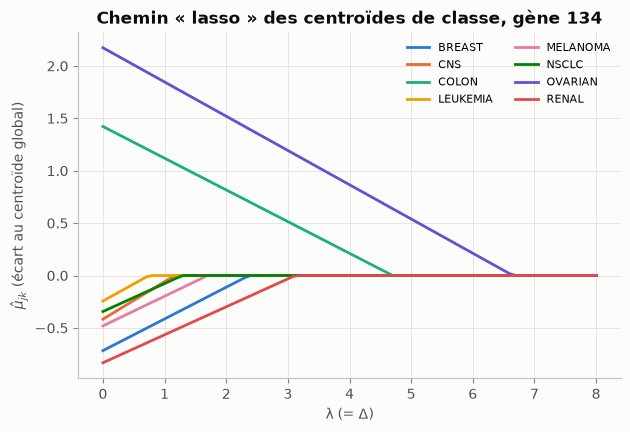

In [4]:
j = int(np.argmax(np.abs(nsc.d_).max(0)))      # un gène très discriminant
lam_grid = np.linspace(0, 8, 81)
fig, ax = plt.subplots(figsize=(7, 4.5))
paths = np.array([nsc.set_delta(l).shrunken_centroids_[:, j] - xbar[j] for l in lam_grid])
for k, c in enumerate(nsc.classes_):
    ax.plot(lam_grid, paths[:, k], color=COLORS[k], label=c)
ax.set_xlabel("λ (= Δ)")
ax.set_ylabel(r"$\hat\mu_{jk}$ (écart au centroïde global)")
ax.set_title(f"Chemin « lasso » des centroïdes de classe, gène {j}")
ax.legend(ncol=2, fontsize=8)
plt.show()

Comme pour un chemin lasso, chaque $\hat\mu_{jk}$ décroît linéairement en valeur absolue
puis s'annule à partir d'un certain $\lambda$ (ici $\lambda = |d_{kj}|$).

> **À retenir.** Les centroïdes réduits sont la solution d'un **lasso** sur les écarts
> de classe $\mu_{jk}$, pénalisés en unités d'écart-type : le seuillage doux est la
> solution explicite de ce lasso, qui se découple variable par variable et classe par
> classe.

## Exercice 18.3 : Somme nulle des coefficients de la multinomiale ridge

**Énoncé (reformulé).** Montrer que les coefficients du problème de régression
logistique multiclasse régularisée (18.10)-(18.11) vérifient
$\sum_{k=1}^K\hat\beta_{kj} = 0$ pour $j = 1,\dots,p$. Qu'en est-il des intercepts
$\hat\beta_{k0}$ ? Discuter les difficultés qu'ils posent et comment les résoudre.

**Rappels.** On note $p_{ik} = \Pr(G = k\mid x_i)$ donné par (18.10) et $y_{ik} = \mathbb 1(g_i = k)$.
La log-vraisemblance est $\ell = \sum_i\big[\sum_k y_{ik}\eta_{ik} - \log\sum_\ell e^{\eta_{i\ell}}\big]$
avec $\eta_{ik} = \beta_{k0} + x_i^T\beta_k$. Comme
$\partial\log\sum_\ell e^{\eta_{i\ell}}/\partial\eta_{ik} = p_{ik}$, on a
$\partial\ell/\partial\beta_{kj} = \sum_i(y_{ik}-p_{ik})x_{ij}$ et
$\partial\ell/\partial\beta_{k0} = \sum_i(y_{ik}-p_{ik})$.

**Solution.**

*Coefficients $\beta_{kj}$.* Le critère (18.11),
$\ell - \frac\lambda2\sum_k\|\beta_k\|^2$, est concave et dérivable ; en un maximum, son
gradient est nul :
$$\sum_{i=1}^N(y_{ik}-p_{ik})x_{ij} - \lambda\hat\beta_{kj} = 0\qquad\text{pour tous } k, j.$$
Sommons sur $k$ : $\sum_k y_{ik} = 1$ (chaque observation est dans une seule classe) et
$\sum_kp_{ik} = 1$ (probabilités), donc $\sum_k(y_{ik}-p_{ik}) = 0$ et il reste
$\lambda\sum_k\hat\beta_{kj} = 0$. Comme $\lambda > 0$ : $\sum_k\hat\beta_{kj} = 0$. $\square$

*Autre preuve (invariance).* Si l'on remplace chaque $\beta_k$ par $\beta_k - c$
($c\in\mathbb R^p$), tous les $\eta_{ik}$ diminuent de $x_i^Tc$ : les probabilités (18.10)
ne changent pas. Seule la pénalité change, et
$c\mapsto\sum_k\|\beta_k - c\|^2$ est minimale en $c = \frac1K\sum_k\beta_k$ (moyenne).
À l'optimum on ne peut pas diminuer la pénalité, donc la moyenne des $\hat\beta_k$ est nulle.

*Intercepts.* Ils ne sont **pas pénalisés**. Le même argument d'invariance montre que
remplacer tous les $\beta_{k0}$ par $\beta_{k0} + c_0$ ($c_0\in\mathbb R$) ne change ni la
vraisemblance ni la pénalité : les intercepts ne sont **pas identifiables** ; il y a
une infinité de solutions (seules les différences $\beta_{k0}-\beta_{\ell 0}$ sont
déterminées). Leur condition d'optimalité $\sum_i(y_{ik} - p_{ik}) = 0$ dit que les
probabilités moyennes ajustées égalent les fréquences observées des classes.

**Remèdes** : imposer une contrainte d'identification, par exemple
$\sum_k\beta_{k0} = 0$ (symétrique) ou $\beta_{K0} = 0$ (classe de référence) ; ou
pénaliser très légèrement les intercepts, ce qui force $\sum_k\hat\beta_{k0} = 0$ par
l'argument précédent. Numériquement, un algorithme de Newton rencontre une hessienne
singulière dans la direction $(1,\dots,1)$ des intercepts ; une contrainte supprime ce
problème.

**Vérification numérique** sur NCI (8 classes), en dimension réduite grâce au
théorème (18.16)-(18.17). On part de deux initialisations différentes des intercepts.

In [5]:
Xn, yn = X_all[keep], lab_all[keep]
R, V = g.svd_reduce(Xn - Xn.mean(0))
K = len(np.unique(yn))
p_r = R.shape[1]
rng = np.random.RandomState(3)
for shift, noise in [(0.0, 0.0), (5.0, 1.0)]:
    w0 = noise * rng.randn((p_r + 1) * K)   # coefficients initiaux (aléatoires ou nuls)
    w0[:K] = shift                          # intercepts initiaux
    cl, B0, B = g.ridge_multinomial(R, yn, 1.0, beta_init=w0)
    beta_full = V @ B                       # coefficients dans l'espace des 6830 gènes
    print(f"init. (intercepts = {shift}, bruit = {noise}) :")
    print(f"   max_j |sum_k beta_kj| = {np.abs(beta_full.sum(1)).max():.1e}  "
          f"(max_j,k |beta_kj| = {np.abs(beta_full).max():.1e})")
    print(f"   sum_k beta_k0 = {B0.sum():+.3f}, intercepts centrés = {np.round(B0 - B0.mean(), 3)}")

init. (intercepts = 0.0, bruit = 0.0) :
   max_j |sum_k beta_kj| = 1.1e-14  (max_j,k |beta_kj| = 3.7e-02)
   sum_k beta_k0 = -0.000, intercepts centrés = [ 0.414 -0.481 -0.341 -0.843  0.208  0.842  0.047  0.152]
init. (intercepts = 5.0, bruit = 1.0) :
   max_j |sum_k beta_kj| = 3.9e-09  (max_j,k |beta_kj| = 3.7e-02)
   sum_k beta_k0 = +40.000, intercepts centrés = [ 0.414 -0.481 -0.341 -0.843  0.208  0.842  0.047  0.152]


Les $\hat\beta_{kj}$ somment à zéro (à la précision de l'optimiseur), même en partant
de coefficients aléatoires dont la somme n'est pas nulle ; la somme des intercepts
dépend de l'initialisation (non-identifiabilité) mais les intercepts **centrés** sont
les mêmes (aux erreurs d'optimisation près).

> **À retenir.** La pénalité quadratique « choisit » la paramétrisation symétrique
> $\sum_k\beta_k = 0$ ; les intercepts non pénalisés restent définis à une constante
> près, qu'il faut fixer par une contrainte.

## Exercice 18.4 : La formule de calcul (18.15)

**Énoncé (reformulé).** Établir la formule (18.15) :
$\hat\beta = \mathbf V(\mathbf R^T\mathbf R + \lambda I)^{-1}\mathbf R^Ty$, où
$\mathbf X = \mathbf R\mathbf V^T$ est la SVD réduite (18.13). *Indication* : utiliser la
dérivée du critère pour montrer que, si $\lambda > 0$, $\hat\beta = \mathbf X^Ts$ pour un
certain $s\in\mathbb R^N$.

**Solution.**

*Étape 1 : $\hat\beta$ est dans l'espace des lignes.* Le critère
$J(\beta) = \|y - \mathbf X\beta\|^2 + \lambda\|\beta\|^2$ est strictement convexe et
dérivable, de gradient $\nabla J(\beta) = -2\mathbf X^T(y-\mathbf X\beta) + 2\lambda\beta$.
En $\hat\beta$, $\nabla J = 0$, donc
$$\hat\beta = \mathbf X^Ts,\qquad s = \frac1\lambda(y - \mathbf X\hat\beta)\in\mathbb R^N .$$
(C'est ici que $\lambda > 0$ sert.)

*Étape 2 : $\hat\beta = \mathbf V\theta$.* Comme $\mathbf X^T = \mathbf V\mathbf R^T$,
$\hat\beta = \mathbf V(\mathbf R^Ts) = \mathbf V\theta$ avec $\theta = \mathbf R^Ts\in\mathbb R^N$.

*Étape 3 : équation pour $\theta$.* La condition $\nabla J(\hat\beta) = 0$ s'écrit
$(\mathbf X^T\mathbf X + \lambda I)\hat\beta = \mathbf X^Ty$. Avec
$\mathbf X^T\mathbf X = \mathbf V\mathbf R^T\mathbf R\mathbf V^T$ et $\mathbf V^T\mathbf V = I_N$ :
$$(\mathbf V\mathbf R^T\mathbf R\mathbf V^T + \lambda I)\mathbf V\theta = \mathbf V\mathbf R^T\mathbf R\theta + \lambda\mathbf V\theta = \mathbf V(\mathbf R^T\mathbf R + \lambda I)\theta = \mathbf V\mathbf R^Ty .$$
En multipliant à gauche par $\mathbf V^T$ : $(\mathbf R^T\mathbf R + \lambda I_N)\theta = \mathbf R^Ty$.
La matrice $\mathbf R^T\mathbf R + \lambda I_N$ est définie positive donc inversible, et
$$\hat\beta = \mathbf V(\mathbf R^T\mathbf R+\lambda I_N)^{-1}\mathbf R^Ty.\qquad\square$$

> **Remarque (identité « push-through »).** On peut aussi vérifier directement que
> $(\mathbf X^T\mathbf X+\lambda I_p)^{-1}\mathbf X^T = \mathbf X^T(\mathbf X\mathbf X^T + \lambda I_N)^{-1}$
> en multipliant à gauche par $\mathbf X^T\mathbf X+\lambda I_p$ et à droite par
> $\mathbf X\mathbf X^T+\lambda I_N$ : les deux membres donnent
> $\mathbf X^T\mathbf X\mathbf X^T + \lambda\mathbf X^T$. On n'inverse alors qu'une
> matrice $N\times N$.

In [6]:
rng = np.random.RandomState(4)
X4, y4 = rng.randn(30, 400), rng.randn(30)
lam = 3.0
R4, V4 = g.svd_reduce(X4)
b1 = np.linalg.solve(X4.T @ X4 + lam * np.eye(400), X4.T @ y4)          # (18.14)
b2 = V4 @ np.linalg.solve(R4.T @ R4 + lam * np.eye(30), R4.T @ y4)      # (18.15)
b3 = X4.T @ np.linalg.solve(X4 @ X4.T + lam * np.eye(30), y4)           # push-through
s = (y4 - X4 @ b1) / lam
print("|(18.14) - (18.15)|        :", np.abs(b1 - b2).max())
print("|(18.14) - push-through|   :", np.abs(b1 - b3).max())
print("|beta - X^T s|              :", np.abs(b1 - X4.T @ s).max())

|(18.14) - (18.15)|        : 1.3877787807814457e-15
|(18.14) - push-through|   : 1.4085954624931674e-15
|beta - X^T s|              : 2.3869795029440866e-15


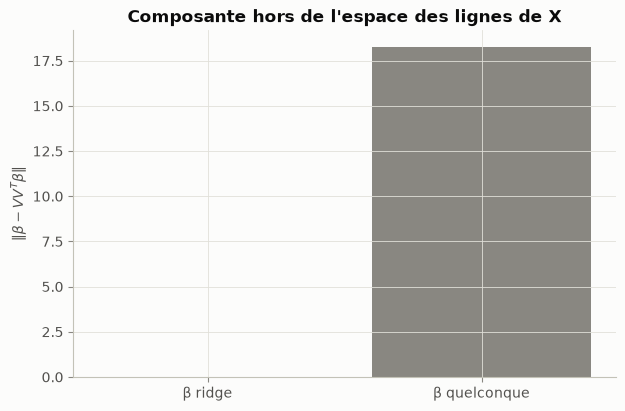

In [7]:
# Visualisation : la part de beta orthogonale à l'espace des lignes est nulle
P_row = V4 @ V4.T
beta_rand = rng.randn(400)
fig, ax = plt.subplots(figsize=(7, 4.5))
vals = [np.linalg.norm(b1 - P_row @ b1), np.linalg.norm(beta_rand - P_row @ beta_rand)]
ax.bar(["β ridge", "β quelconque"], vals, color=[BLUE, GRAY])
ax.set_ylabel(r"$\|\beta - VV^T\beta\|$")
ax.set_title("Composante hors de l'espace des lignes de X")
plt.show()

> **À retenir.** Toute solution ridge vit dans l'espace engendré par les $N$
> observations ; on peut donc calculer en dimension $N$ et revenir en dimension $p$
> par $\hat\beta = \mathbf V\hat\theta$.

## Exercice 18.5 : Preuve du théorème (18.16)-(18.17)

**Énoncé (reformulé).** Démontrer le théorème de la section 18.3.5 : pour toute perte
$L$, si $(\hat\theta_0,\hat\theta)$ minimise
$\sum_iL(y_i,\theta_0 + r_i^T\theta) + \lambda\theta^T\theta$ sur $\mathbb R\times\mathbb R^N$,
alors $(\hat\beta_0,\hat\beta) = (\hat\theta_0,\mathbf V\hat\theta)$ minimise
$\sum_iL(y_i,\beta_0 + x_i^T\beta) + \lambda\beta^T\beta$ sur $\mathbb R\times\mathbb R^p$.
*Indication* : décomposer $\beta$ et les lignes de $\mathbf X$ selon l'espace engendré
par les colonnes de $\mathbf V$ et son orthogonal.

**Solution.** Notons $\mathcal V = \operatorname{Im}(\mathbf V)\subset\mathbb R^p$ (dimension
$N$) et $\mathcal V^\perp$ son orthogonal. Notons $C_p(\beta_0,\beta)$ et
$C_N(\theta_0,\theta)$ les deux critères.

*Lignes de $\mathbf X$.* De $\mathbf X = \mathbf R\mathbf V^T$, la ligne $i$ vérifie
$x_i = \mathbf Vr_i\in\mathcal V$ : elle n'a pas de composante dans $\mathcal V^\perp$.

*Décomposition de $\beta$.* Tout $\beta\in\mathbb R^p$ s'écrit de façon unique
$\beta = \mathbf V\theta + \beta_\perp$ avec $\theta = \mathbf V^T\beta$ et
$\beta_\perp\in\mathcal V^\perp$ (projection orthogonale ; $\mathbf V^T\mathbf V = I_N$).

*Prédicteur linéaire.* $x_i^T\beta = r_i^T\mathbf V^T(\mathbf V\theta + \beta_\perp) = r_i^T\theta + r_i^T\underbrace{\mathbf V^T\beta_\perp}_{=0} = r_i^T\theta$.

*Pénalité.* Par Pythagore ($\mathbf V\theta\perp\beta_\perp$) et $\|\mathbf V\theta\| = \|\theta\|$ :
$\beta^T\beta = \theta^T\theta + \beta_\perp^T\beta_\perp$.

*Conclusion.* Pour tout $(\beta_0,\beta)$ :
$$C_p(\beta_0,\beta) = C_N(\beta_0,\theta) + \lambda\|\beta_\perp\|^2\ \ge\ C_N(\beta_0,\theta)\ \ge\ C_N(\hat\theta_0,\hat\theta) = C_p(\hat\theta_0,\mathbf V\hat\theta).$$
Donc $(\hat\theta_0,\mathbf V\hat\theta)$ minimise $C_p$. Réciproquement, tout minimiseur de
$C_p$ a $\beta_\perp = 0$ (sinon on diminue strictement $C_p$ en annulant $\beta_\perp$,
puisque $\lambda > 0$) et $(\beta_0,\mathbf V^T\beta)$ minimise $C_N$ : si le minimiseur de
$C_N$ est unique, celui de $C_p$ l'est aussi. $\square$

> **Intuition.** La perte ne « voit » que la projection de $\beta$ sur l'espace des
> données ; la composante orthogonale ne fait qu'augmenter la pénalité. Cela tient à
> l'invariance de $\|\beta\|_2^2$ par rotation ; avec $\|\beta\|_1$ (lasso) la
> décomposition de Pythagore n'existe plus et le résultat est faux.

**Vérification numérique avec une autre perte** : la perte « charnière au carré »
$L(y,f) = \max(0, 1 - yf)^2$ (une variante lisse du SVM), $y\in\{-1,+1\}$. On minimise
les deux critères par L-BFGS, en dimension $p = 300$ puis $N = 25$.

In [8]:
def sq_hinge_fit(X, y, lam):
    n, d = X.shape
    def fg(w):
        b0, b = w[0], w[1:]
        m = np.maximum(0, 1 - y * (b0 + X @ b))
        f = np.sum(m ** 2) + lam * b @ b
        gm = -2 * m * y
        return f, np.r_[gm.sum(), X.T @ gm + 2 * lam * b]
    res = optimize.minimize(fg, np.zeros(d + 1), jac=True, method="L-BFGS-B",
                            options={"maxiter": 10000, "gtol": 1e-10, "ftol": 1e-15})
    return res.x[0], res.x[1:]


rng = np.random.RandomState(5)
X5 = rng.randn(25, 300)
y5 = np.where(X5[:, 0] + 0.5 * rng.randn(25) > 0, 1.0, -1.0)
b0_p, b_p = sq_hinge_fit(X5, y5, 0.5)
R5, V5 = g.svd_reduce(X5)
t0_n, t_n = sq_hinge_fit(R5, y5, 0.5)
print(f"|beta0 - theta0|      = {abs(b0_p - t0_n):.1e}")
print(f"max|beta - V theta|   = {np.abs(b_p - V5 @ t_n).max():.1e}")
print(f"||beta_perp||         = {np.linalg.norm(b_p - V5 @ (V5.T @ b_p)):.1e}")

|beta0 - theta0|      = 1.9e-09
max|beta - V theta|   = 2.0e-10
||beta_perp||         = 4.5e-14


**Contre-exemple avec la pénalité L1** : le lasso calculé sur $\mathbf R$ puis
remonté par $\mathbf V$ n'est **pas** le lasso sur $\mathbf X$ (il n'est même pas
parcimonieux).

In [ ]:
rng = np.random.RandomState(6)
X6 = rng.randn(20, 100)
y6 = X6[:, :3].sum(1) + 0.3 * rng.randn(20)
b_lasso = g.lasso_cd(X6, y6, 2.0, tol=1e-10)
R6, V6 = g.svd_reduce(X6)
b_wrong = V6 @ g.lasso_cd(R6, y6, 2.0, tol=1e-10)
crit = lambda b: 0.5 * np.sum((y6 - X6 @ b) ** 2) + 2.0 * np.abs(b).sum()
print(f"lasso sur X        : {np.count_nonzero(b_lasso):3d} coefficients non nuls, critère {crit(b_lasso):.3f}")
print(f"V x (lasso sur R)  : {np.count_nonzero(np.abs(b_wrong) > 1e-10):3d} coefficients non nuls, critère {crit(b_wrong):.3f}")